# Bài tập Heatmap (SLIDE 3)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

mat = pd.read_csv("student-mat.csv", sep=";")
por = pd.read_csv("student-por.csv", sep=";")
df = pd.concat([mat, por], ignore_index=True)
df.shape

(1044, 33)

Pyplot không có sẵn hàm heatmap có ghi số, nên viết một hàm dùng chung cho cả 5 câu.

In [2]:
def ve_heatmap(bang, tieu_de):
    plt.figure(figsize=(7, 4))
    plt.imshow(bang.values, cmap="Blues")
    plt.colorbar()
    plt.xticks(range(bang.shape[1]), bang.columns)
    plt.yticks(range(bang.shape[0]), bang.index)
    giua = (np.nanmin(bang.values) + np.nanmax(bang.values)) / 2
    for i in range(bang.shape[0]):
        for j in range(bang.shape[1]):
            v = bang.values[i, j]
            if not np.isnan(v):                      # ô không có dữ liệu thì để trống
                mau = "white" if v > giua else "black"
                plt.text(j, i, f"{v:.2f}", ha="center", va="center", color=mau)
    plt.title(tieu_de)
    plt.show()

## Câu 1. Trường (GP, MS) và giới tính: điểm trung bình G1-G3

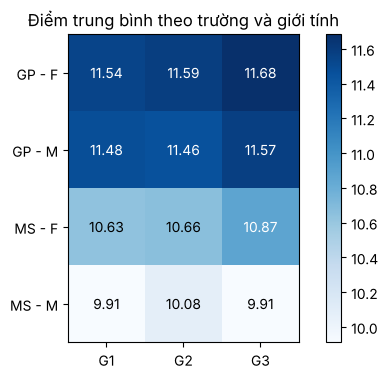

In [3]:
bang = df.groupby(["school", "sex"])[["G1", "G2", "G3"]].mean()
bang.index = [" - ".join(i) for i in bang.index]    # gộp 2 cấp index thành 1 nhãn, vd "GP - F"
ve_heatmap(bang, "Điểm trung bình theo trường và giới tính")

**Nhận xét.** GP cao hơn MS ở cả 3 kỳ. Ở GP nam và nữ gần như bằng nhau (khoảng 11,5). Ở MS nữ (10,6 đến 10,9) cao hơn nam (9,9 đến 10,1).
Nhóm thấp nhất là nam trường MS, có G3 = 9,91 (dưới 10).

## Câu 2. Đô thị (U) hay nông thôn (R), có Internet hay không

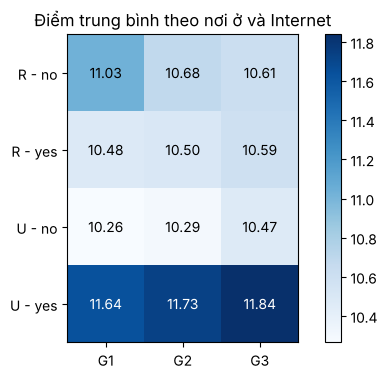

In [4]:
bang = df.groupby(["address", "internet"])[["G1", "G2", "G3"]].mean()
bang.index = [" - ".join(i) for i in bang.index]
ve_heatmap(bang, "Điểm trung bình theo nơi ở và Internet")

**Nhận xét.** Nhóm **đô thị có Internet** cao nhất ở cả 3 kỳ (11,64 / 11,73 / 11,84) và cũng đông nhất (638 em).
Đô thị không có Internet thấp nhất ở G3 (10,47). Ở nông thôn, có hay không có Internet gần như không khác nhau ở G3 (10,59 và 10,61).
Vậy Internet chỉ thấy rõ tác dụng ở nhóm đô thị.

## Câu 3. Hỗ trợ ở trường (schoolsup) và ở nhà (famsup)

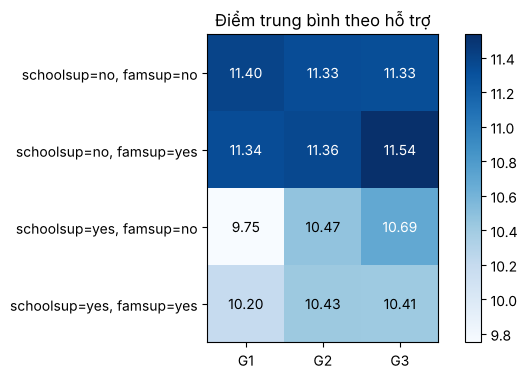

schoolsup  famsup
no         no        372
           yes       553
yes        no         32
           yes        87
dtype: int64


In [5]:
bang = df.groupby(["schoolsup", "famsup"])[["G1", "G2", "G3"]].mean()
bang.index = ["schoolsup=" + a + ", famsup=" + b for a, b in bang.index]
ve_heatmap(bang, "Điểm trung bình theo hỗ trợ")
print(df.groupby(["schoolsup", "famsup"]).size())    # xem số lượng mỗi nhóm

**Nhận xét.** Nhóm **có schoolsup** có điểm thấp hơn nhóm không có (G3 khoảng 10,4 đến 10,7 so với 11,3 đến 11,5), nhưng nhóm này rất nhỏ (32 và 87 em)
và thường là những em vốn học yếu mới được hỗ trợ. Nhóm có famsup nhưng không có schoolsup có G3 cao nhất (11,54).
Chưa kết luận được hỗ trợ làm tăng điểm.

## Câu 4. Cha mẹ sống chung (T) hay riêng (A), theo mức quan hệ gia đình (famrel)

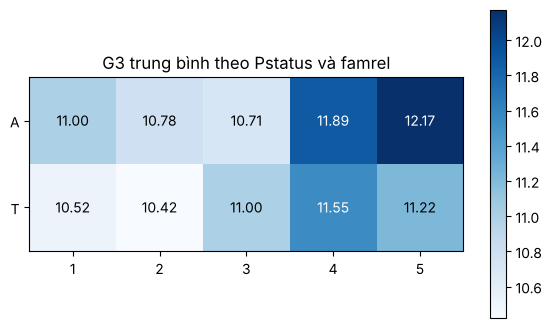

famrel    1   2    3    4    5
Pstatus                       
A         7   9   17   53   35
T        23  38  152  459  251


In [6]:
bang = df.pivot_table(index="Pstatus", columns="famrel", values="G3")
ve_heatmap(bang, "G3 trung bình theo Pstatus và famrel")
print(df.pivot_table(index="Pstatus", columns="famrel", values="G3", aggfunc="count"))

**Nhận xét.** Hai nhóm T và A không khác nhau nhiều (trung bình G3: 11,30 và 11,67). Em có quan hệ gia đình tốt (famrel 4 đến 5) có G3 cao hơn
(khoảng 11,2 đến 12,2) so với famrel 1 đến 3 (khoảng 10,4 đến 11,0). Nhóm A ở famrel 1 đến 3 chỉ có 7, 9 và 17 em nên số liệu chưa chắc chắn.

## Câu 5. Thời gian học (studytime) và số lần trượt môn (failures)

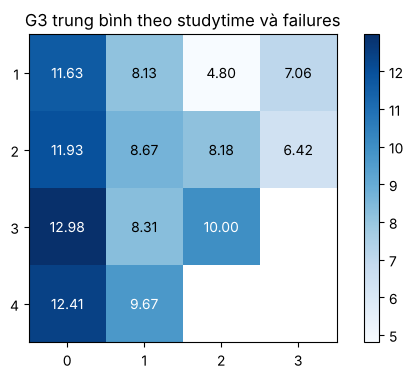

failures       0     1     2     3
studytime                         
1          237.0  52.0  10.0  18.0
2          422.0  52.0  17.0  12.0
3          143.0  13.0   6.0   NaN
4           59.0   3.0   NaN   NaN


In [7]:
bang = df.pivot_table(index="studytime", columns="failures", values="G3")
ve_heatmap(bang, "G3 trung bình theo studytime và failures")
print(df.pivot_table(index="studytime", columns="failures", values="G3", aggfunc="count"))

**Nhận xét.** Số lần trượt ảnh hưởng mạnh hơn thời gian học. Em chưa trượt lần nào (failures = 0) có G3 khoảng 11,6 đến 13,0, còn chỉ cần trượt 1 lần là giảm xuống còn khoảng 8 đến 9,7.
Ở nhóm failures = 0, học nhiều hơn thì điểm cao hơn (11,63 lên 12,98 ở mức 5 đến 10 giờ). Các ô failures từ 1 trở lên có rất ít em (từ 3 đến 52), và một số ô
trống vì không có em nào, nên xu hướng ở đó không đáng tin.